# GAN và diffusion

Ta cần tạo nhiều kiểu biểu tượng sách cho một bài thực hành, thay vì chọn một ảnh đã chụp. Model sinh ảnh học phân phối của ảnh, rồi sinh mẫu mới từ nguồn ngẫu nhiên và có thể thêm điều kiện chữ. Câu hỏi xuyên suốt là: làm sao một tín hiệu ngẫu nhiên thành ảnh có cấu trúc, và vì sao một ảnh trông đẹp chưa đủ để chứng minh model sinh tốt?

> **Mục tiêu sau bài này**
>
> - Phân biệt hai vai trò generator/discriminator của GAN.
> - Viết một bước cập nhật GAN đúng đường gradient.
> - Tính bước thêm nhiễu và mục tiêu dự đoán nhiễu của diffusion.
> - Đọc quy trình sinh có điều kiện (sampler, latent, guidance), ước lượng thời gian và so cấu hình bằng seed, prompt cố định.

## Sinh mẫu khác với dự đoán nhãn

Classifier ước lượng nhãn theo ảnh. Model sinh cần mô tả sự biến thiên của dữ liệu: những kiểu ảnh nào có thể xuất hiện và xuất hiện với tần suất nào. Nếu luôn trả cùng một ảnh đẹp, model bỏ mất sự đa dạng.

Nguồn noise $z$ không phải lỗi cần xóa: nó cung cấp biến thiên để cùng một prompt cho nhiều mẫu. Seed cố định dãy số ngẫu nhiên, nên hai seed cho hai noise khác nhau, còn cùng seed trong cùng điều kiện cho lại cùng thí nghiệm. “Cùng điều kiện” gồm cả model, sampler, phiên bản thư viện và phần cứng: đổi một thứ, ảnh có thể khác dù seed giữ nguyên.

**Hỏi nhanh.** Một đội giữ nguyên seed 7, prompt và model, chỉ đổi sampler, chạy trên cùng một máy. Ảnh ra khác hẳn. Vì sao?

- A. Seed chỉ cố định các số ngẫu nhiên, còn sampler đổi cách đi từ noise tới ảnh
- B. Đổi sampler làm seed bị bỏ qua, nên noise ban đầu được lấy lại ngẫu nhiên
- C. Cùng seed thì phải cùng ảnh, nên ảnh khác nghĩa là máy đang tính sai
- D. Mỗi sampler đi kèm trọng số riêng, nên thực chất model đã bị đổi

<details><summary>Đáp án</summary>

A. Seed chỉ cố định các số ngẫu nhiên, còn sampler đổi cách đi từ noise tới ảnh

Seed quyết định các số ngẫu nhiên được rút ra, gồm noise ban đầu và noise thêm ở từng bước nếu sampler có dùng. Sampler quyết định dùng các số ấy và dự đoán của model thế nào để đi tới ảnh, kể cả rút ra bao nhiêu số. Đổi sampler là đổi cả quỹ đạo. Seed không bị bỏ qua, máy không tính sai, và sampler là thuật toán dùng chung một model đã train.

</details>

## GAN: hai mạng có hai mục tiêu

Generator $G(z)$ biến noise thành mẫu giả. Discriminator $D(x)$ học phân biệt mẫu thật với mẫu do generator tạo. Generator được cập nhật để discriminator đánh giá mẫu giả như thật. Hai mạng thay đổi cùng quá trình, nên mục tiêu mà một mạng thấy cũng đang thay đổi.



Một cách train thông dụng dùng binary cross-entropy. Discriminator muốn nhãn 1 cho thật, 0 cho giả:

$$L_D=-\E_x\log D(x)-\E_z\log(1-D(G(z))).$$

Với non-saturating generator loss, generator muốn fake được D chấm 1:

$$L_G=-\E_z\log D(G(z)).$$

Với $D(G(z))=0.2$, loss này là $-\log0.2\approx1.609$; nếu G đẩy được điểm lên 0.8 thì loss còn khoảng 0.223.

Cách viết minimax nguyên thủy cho G cực tiểu $\E_z\log(1-D(G(z)))$. Hai cách cùng hướng đẩy $D(G(z))$ lên, nhưng khác nhau ở độ lớn gradient. Viết $D=\sigma(a)$ với $a$ là logit của fake:

$$\frac{\partial}{\partial a}\log(1-\sigma(a))=-\sigma(a),\qquad
\frac{\partial}{\partial a}\bigl(-\log\sigma(a)\bigr)=-(1-\sigma(a)).$$

Đầu train, D dễ nhận ra fake nên $D(G(z))$ gần 0. Khi đó cách viết minimax cho gradient gần 0 (bão hòa) và G gần như đứng yên, còn non-saturating cho gradient có độ lớn gần 1. Vì vậy code thực hành dùng $L_G=-\E_z\log D(G(z))$, tức BCE với nhãn “thật” cho fake.



**Hỏi nhanh.** Đầu train, D dễ nhận ra ảnh giả: $D(G(z)) = 0.01$. Tính theo logit $a$ của ảnh giả, độ lớn gradient của $\log(1 - D)$, tức loss minimax, và của $-\log D$, tức loss non-saturating, lần lượt là bao nhiêu?

- A. $0.99$ và $0.01$
- B. $0.01$ và $0.99$
- C. $0.01$ và $4.61$
- D. Bằng nhau, vì hai loss cùng đẩy $D(G(z))$ lên

<details><summary>Đáp án</summary>

B. $0.01$ và $0.99$

Theo công thức đạo hàm, minimax cho $\sigma(a) = 0.01$, còn non-saturating cho $1 - \sigma(a) = 0.99$, gấp 99 lần. Đảo hai số là nhớ ngược công thức. $4.61 = -\ln 0.01$ là giá trị loss, không phải gradient. Cùng hướng chưa có nghĩa là cùng độ lớn, và đó chính là lý do người ta chọn non-saturating.

</details>

## Một bước GAN thật, nhưng trên số một chiều

Trước khi train GAN ảnh, nên kiểm đồ thị gradient trên một bài nhỏ đến mức đọc được từng tham số: dữ liệu thật là bốn số quanh 2, `G` và `D` mỗi mạng là một lớp tuyến tính. Điều cần nhìn là tham số nào đổi ở bước nào; giá trị loss của một bước chưa nói gì về chất lượng sinh.

In [ ]:
import numpy as np
import torch
from torch import nn

torch.set_num_threads(1)
torch.manual_seed(58)
generator = nn.Linear(1, 1)
discriminator = nn.Linear(1, 1)
optimizer_g = torch.optim.SGD(generator.parameters(), lr=0.1)
optimizer_d = torch.optim.SGD(discriminator.parameters(), lr=0.1)
real = torch.tensor([[1.7], [1.9], [2.1], [2.3]])
noise = torch.tensor([[-1.], [0.], [1.], [2.]])
criterion = nn.BCEWithLogitsLoss()

g_before_d = generator.weight.detach().clone()
optimizer_d.zero_grad()
fake = generator(noise)
real_logits = discriminator(real)
fake_logits = discriminator(fake.detach())
loss_d = criterion(real_logits, torch.ones_like(real_logits))
loss_d += criterion(fake_logits, torch.zeros_like(fake_logits))
loss_d.backward()
optimizer_d.step()
print("G unchanged during D step:", torch.equal(g_before_d, generator.weight))
print("D loss:", round(loss_d.item(), 4))

G unchanged during D step: True
D loss: 1.4571


D loss 1.4571 gần $2\ln2\approx1.386$, mức của một D chấm 0.5 cho mọi mẫu: D mới khởi tạo chưa phân biệt được thật và giả. `detach()` ở fake làm gradient của bước D không đi vào G. Bước tiếp theo giữ trọng số D nhưng vẫn cần đạo hàm của D theo đầu vào:

In [ ]:
d_before_g = discriminator.weight.detach().clone()
g_before_g = generator.weight.detach().clone()
for parameter in discriminator.parameters():
    parameter.requires_grad_(False)
optimizer_g.zero_grad()
fake = generator(noise)
fake_logits = discriminator(fake)
loss_g = criterion(fake_logits, torch.ones_like(fake_logits))
loss_g.backward()
optimizer_g.step()
for parameter in discriminator.parameters():
    parameter.requires_grad_(True)
print("D unchanged during G step:", torch.equal(d_before_g, discriminator.weight))
print("G changed during G step:", not torch.equal(g_before_g, generator.weight))
print("G loss:", round(loss_g.item(), 4))
print("hand loss for D(fake)=0.2:", round(-np.log(0.2), 4))

D unchanged during G step: True
G changed during G step: True
G loss: 1.0656
hand loss for D(fake)=0.2: 1.6094


G loss 1.0656 ứng với trung bình nhân của $D(G(z))$ khoảng $e^{-1.0656}\approx0.34$: D vẫn nghiêng về “giả”, nên G còn tín hiệu để học. Dòng cuối kiểm lại số tính tay ở mục trước.

Không đặt `no_grad()` quanh D trong bước G: như vậy sẽ cắt đường gradient cần về G. Đóng băng parameter D vẫn giữ phép tính theo fake. Ba dòng kiểm tham số phát hiện loại bug này trước khi chạy một GAN lớn.

GAN có thể dao động, discriminator quá mạnh hoặc generator chỉ sinh vài kiểu (mode collapse). Loss G/D không có quy tắc “càng thấp đồng thời càng tốt” giống supervised loss cố định. Cần xem chất lượng, đa dạng và metric phù hợp trên nhiều seed.

**Hỏi nhanh.** Xóa `.detach()` ở bước D rồi chạy lại. Dòng kiểm vẫn in `G unchanged during D step: True`. Ta kết luận được gì?

- A. Bỏ `detach()` là an toàn, vì phép kiểm đã in True
- B. Trọng số G không đổi, nhưng `.grad` của G đã bị ghi
- C. Phép kiểm sai, trọng số G thật ra đã bị cập nhật
- D. Có detach hay không thì gradient bước D cũng không tới được G

<details><summary>Đáp án</summary>

B. Trọng số G không đổi, nhưng `.grad` của G đã bị ghi

`loss_d.backward()` lan ngược qua ảnh giả tới G và ghi gradient vào `generator.weight.grad`. `optimizer_d.step()` chỉ giữ tham số của D, nên trọng số G không đổi, và phép kiểm vẫn đúng là True. Code này gọi `optimizer_g.zero_grad()` ngay trước bước G, nên gradient thừa bị xóa. Nếu vòng lặp xóa gradient ở chỗ khác, gradient “đẩy ảnh giả về phía giả” sẽ cộng vào bước G. Lần nào cũng tốn thêm một lượt backward qua G. Kiểm trọng số không thay được việc nhìn vào `.grad`.

</details>

**Hỏi nhanh.** Ở bước G, ta bọc dòng `fake_logits = discriminator(fake)` trong `torch.no_grad()`, còn `fake = generator(noise)` vẫn ở ngoài. Chuyện gì xảy ra?

- A. G vẫn học, vì `fake` được tạo ngoài khối `no_grad`
- B. Code chạy được nhưng chỉ cập nhật D, vì D nằm trong khối
- C. `loss_g.backward()` báo lỗi, vì loss không còn nối tới G
- D. G học chậm hơn, vì gradient qua D bị thu nhỏ lại

<details><summary>Đáp án</summary>

C. `loss_g.backward()` báo lỗi, vì loss không còn nối tới G

Trong khối `no_grad()`, `fake_logits` không có `grad_fn`. Loss chỉ gồm số hạng này, nên `backward()` báo lỗi “does not require grad”. `fake` có gradient cũng không cứu được, vì đường đi bị cắt ngay tại D. Nếu loss còn số hạng khác nối với G, code sẽ chạy im lặng nhưng G không nhận tín hiệu nào từ D, còn khó phát hiện hơn. Khối `no_grad` không đổi việc optimizer nào cập nhật tham số nào. Nó cũng không làm gradient nhỏ đi một phần, mà cắt hẳn.

</details>

## Diffusion: học sửa ảnh ở nhiều mức nhiễu

Thay vì đối đầu hai mạng, diffusion tạo một nhiệm vụ supervised từ dữ liệu: thêm noise đã biết vào mẫu sạch, rồi học đoán noise hoặc đại lượng tương đương. Lúc sinh, bắt đầu từ noise và làm nhiều bước khử nhiễu theo scheduler đã định nghĩa.



Đặt $\beta_t$ là mức nhiễu mỗi bước, $\alpha_t=1-\beta_t$, $\bar\alpha_t=\prod_{s=1}^t\alpha_s$. Có thể lấy trực tiếp mẫu nhiễu ở thời điểm $t$:

$$x_t=\sqrt{\bar\alpha_t}\,x_0+\sqrt{1-\bar\alpha_t}\,\epsilon,\qquad
\epsilon\sim\mathcal N(0,I).$$

$x_0$ là dữ liệu sạch; $t$ là mức noise, không phải epoch. Hệ số căn bậc hai phân phối phần phương sai cho tín hiệu và noise. Khi $\bar\alpha_t$ gần 1, giữ nhiều tín hiệu; gần 0, mẫu gần noise. Noise predictor cần nhận cả $x_t$ và $t$ vì cùng một giá trị nhiễu ở mức khác có ý nghĩa khác.



### Ví dụ tính tay

Với $x_0=2$, $\bar\alpha_t=0.64$, $\epsilon=0.5$, ta có $x_t=0.8\cdot2+0.6\cdot0.5=1.9$. Target khi train noise predictor là 0.5, không phải 2. Khi có dự đoán noise $\hat\epsilon$, có thể ước lượng sạch bằng $(x_t-\sqrt{1-\bar\alpha_t}\hat\epsilon)/\sqrt{\bar\alpha_t}$; đây chưa phải toàn bộ sampler.

In [ ]:
clean = 2.0
alpha_bar_example = 0.64
epsilon_example = 0.5
noisy = np.sqrt(alpha_bar_example) * clean
noisy += np.sqrt(1 - alpha_bar_example) * epsilon_example
estimated_clean = (noisy - np.sqrt(1 - alpha_bar_example) * epsilon_example)
estimated_clean /= np.sqrt(alpha_bar_example)
print("noisy:", round(noisy, 4))
print("reconstruction with known noise:", round(estimated_clean, 4))

noisy: 1.9
reconstruction with known noise: 2.0


Ta dùng noise thật ở dòng khôi phục, nên kết quả 2 là kiểm đại số, **không** phải model đã học khử nhiễu. Ở lúc sinh, ảnh sạch chưa biết và noise phải được model ước lượng.

**Hỏi nhanh.** Trong ví dụ tính tay có $x_0 = 2$, $\bar\alpha_t = 0.64$, $\epsilon = 0.5$ và $x_t = 1.9$. Một mẫu train của noise predictor gồm đầu vào và target nào?

- A. Đầu vào $(x_0 = 2,\ t)$, target $x_t = 1.9$
- B. Đầu vào $x_t = 1.9$, bỏ $t$, target $\epsilon = 0.5$
- C. Đầu vào $(x_t = 1.9,\ t)$, target $x_0 = 2$
- D. Đầu vào $(x_t = 1.9,\ t)$, target $\epsilon = 0.5$

<details><summary>Đáp án</summary>

D. Đầu vào $(x_t = 1.9,\ t)$, target $\epsilon = 0.5$

Lúc sinh ta chỉ có mẫu nhiễu, nên đầu vào phải là $x_t$. Target là noise đã rút ra để tạo $x_t$, có sẵn miễn phí khi train. Thiếu $t$ thì cùng giá trị 1.9 ở các mức nhiễu khác nhau sẽ cần target khác nhau. Đoán $x_0$ là một cách tham số hóa khác, không phải noise predictor. Đoán $x_t$ từ $x_0$ chỉ là chạy lại công thức forward, không học gì cả.

</details>

## Train noise predictor trên CPU với dữ liệu một chiều

Thí nghiệm sau train thật một noise predictor trên dữ liệu một chiều: mỗi mẫu sạch nằm quanh $-2$ hoặc $+2$, mức nhiễu lấy ngẫu nhiên trong 40 mức (chỉ số 0–39), MLP nhận $x_t$ cùng chỉ số mức chia cho 39 và đoán $\epsilon$. Cơ chế giống hệt khi train trên ảnh; chỉ khác là $x_0$ là một số thay cho tensor ảnh, và mạng là MLP thay cho U-Net.

Loss là MSE giữa $\epsilon$ và dự đoán. DDPM xuất phát từ mục tiêu likelihood; sau khi rút gọn, mỗi số hạng thành bình phương sai số giữa $\epsilon$ và $\epsilon_\theta(x_t,t)$ nhân một trọng số theo $t$, và bài báo bỏ trọng số ấy để được MSE đơn giản trên noise.

In [ ]:
torch.manual_seed(580)
steps = 40
betas = torch.linspace(0.01, 0.15, steps)
alpha_bars = torch.cumprod(1 - betas, dim=0)
denoiser = nn.Sequential(nn.Linear(2, 24), nn.Tanh(), nn.Linear(24, 1))
optimizer = torch.optim.Adam(denoiser.parameters(), lr=0.01)

def make_noisy_batch(count):
    clean = (torch.randint(0, 2, (count, 1)) * 4 - 2).float()
    clean += 0.2 * torch.randn(count, 1)
    times = torch.randint(0, steps, (count,))
    eps = torch.randn(count, 1)
    kept = alpha_bars[times, None]
    noisy = kept.sqrt() * clean + (1 - kept).sqrt() * eps
    inputs = torch.cat([noisy, times[:, None] / (steps - 1)], dim=1)
    return inputs, eps

valid_inputs, valid_noise = make_noisy_batch(128)
with torch.no_grad():
    before = nn.functional.mse_loss(denoiser(valid_inputs), valid_noise).item()
for update in range(250):
    inputs, targets = make_noisy_batch(64)
    optimizer.zero_grad()
    loss = nn.functional.mse_loss(denoiser(inputs), targets)
    loss.backward()
    optimizer.step()
with torch.no_grad():
    after = nn.functional.mse_loss(denoiser(valid_inputs), valid_noise).item()
    zero_baseline = valid_noise.square().mean().item()
print("noise MSE before/after:", round(before, 4), round(after, 4))
print("zero predictor MSE:", round(zero_baseline, 4))
print("last alpha_bar:", round(alpha_bars[-1].item(), 4))

noise MSE before/after: 0.9092 0.3434
zero predictor MSE: 0.9815
last alpha_bar: 0.0342


MSE giảm từ 0.9092 xuống 0.3434, thấp hơn nhiều so với baseline luôn đoán 0 (0.9815): model đã học. Ở mức cuối, $\bar\alpha=0.0342$: tín hiệu chỉ còn hệ số $\sqrt{0.0342}\approx0.18$, nên mẫu ở mức này đã gần noise chuẩn.



MSE không thể về 0, vì cùng một $x_t$ có thể đến từ nhiều cặp $(x_0,\epsilon)$. Ở mức nhiễu thấp, noise nhỏ hơn độ lệch tự nhiên của $x_0$ quanh $\pm2$ nên không tách được; ở mức giữa, không biết $x_t$ đến từ cụm $-2$ hay $+2$. Con số này đo việc đoán noise; chất lượng mẫu sinh còn phụ thuộc sampler và cần đánh giá riêng.

**Hỏi nhanh.** Ở một mức $t$ có $\bar\alpha_t = 0.001$, noise predictor đoán $\epsilon$ từ $x_t$ dễ hay khó?

- A. Dễ, vì $x_t \approx \epsilon$, gần như đọc thẳng được noise
- B. Khó nhất, vì tín hiệu gần mất hết, không còn gì để dựa vào
- C. Không xác định, vì phải biết $x_0$ mới tính được $\epsilon$
- D. Khó, vì noise lớn nên MSE ở mức này luôn lớn nhất

<details><summary>Đáp án</summary>

A. Dễ, vì $x_t \approx \epsilon$, gần như đọc thẳng được noise

$x_t = \sqrt{0.001}\,x_0 + \sqrt{0.999}\,\epsilon \approx 0.03\,x_0 + \epsilon$. Với $x_0$ quanh $\pm 2$, phần tín hiệu chỉ cỡ 0.06, nên đoán $\epsilon \approx x_t$ đã gần đúng. Ở mức này, khó là đoán $x_0$ chứ không phải đoán $\epsilon$. Không cần biết chính xác $x_0$, vì phần của nó trong $x_t$ quá nhỏ. Với noise predictor, những mức khó là mức nhiễu thấp và mức giữa.

</details>



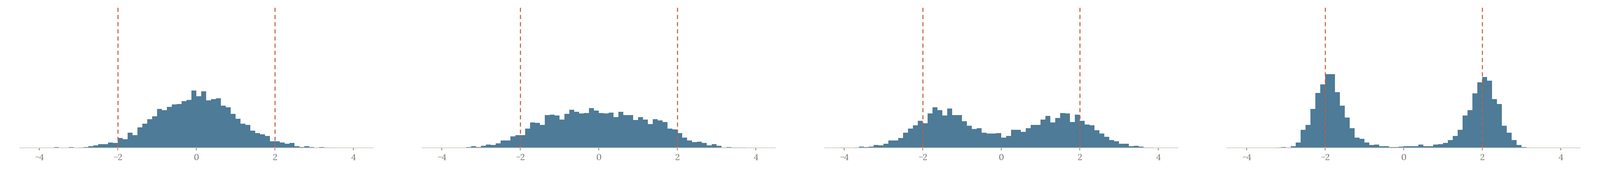

## Từ noise predictor đến model sinh có điều kiện

Sampler bắt đầu từ $x_T\sim\mathcal N(0,I)$ và dùng dự đoán noise ở từng mức để đi về $x_{T-1},\dots,x_0$; tùy scheduler, mỗi bước có thể thêm một lượng noise mới. Lặp công thức khôi phục $x_0$ ở trên không phải là DDPM: hệ số và phương sai của bước reverse phải khớp lịch nhiễu đã dùng khi train ([DDPM](https://arxiv.org/abs/2006.11239) §3.2 viết đủ các hệ số này). Mỗi bước là một lần gọi denoiser, và bước sau cần kết quả bước trước: 50 bước là 50 lần forward nối tiếp cho một ảnh, trong khi generator GAN chỉ cần một.

Text-conditioned diffusion đưa embedding của prompt vào denoiser, thường qua cross-attention. Latent diffusion (họ Stable Diffusion) chạy cả quá trình trong latent nén của ảnh: encoder của một autoencoder nén ảnh, khử nhiễu diễn ra trên latent, decoder biến latent cuối thành pixel. Stable Diffusion 1.x dùng latent $64\times64\times4$ cho ảnh $512\times512\times3$, nên mỗi lần gọi denoiser rẻ hơn nhiều.

**Hỏi nhanh.** Dùng latent $64\times 64\times 4$ thay cho ảnh $512\times 512\times 3$. Mỗi lần gọi denoiser xử lý ít hơn bao nhiêu lần số giá trị?

- A. 8 lần
- B. 48 lần
- C. 64 lần
- D. 192 lần

<details><summary>Đáp án</summary>

B. 48 lần

$512\cdot 512\cdot 3 = 786\,432$ và $64\cdot 64\cdot 4 = 16\,384$, tỉ lệ là 48. 8 là tỉ lệ cạnh. 64 là tỉ lệ diện tích, quên số kênh. 192 chỉ tính 3 kênh của ảnh mà quên 4 kênh của latent.

</details>



Classifier-free guidance (CFG) điều khiển mức bám prompt. Mỗi bước gọi denoiser hai lần, có prompt $c$ và không prompt $\varnothing$, rồi đẩy dự đoán ra xa bản không điều kiện:

$$\hat\epsilon=\epsilon_\theta(x_t,t,\varnothing)+w\,\bigl[\epsilon_\theta(x_t,t,c)-\epsilon_\theta(x_t,t,\varnothing)\bigr].$$

$w=1$ là dự đoán có điều kiện thường. $w$ lớn hơn làm ảnh bám prompt hơn, đổi lại đa dạng giảm và màu, chi tiết có thể quá gắt; mỗi bước cũng tốn gấp đôi. Model học cả hai chế độ nhờ khi train bỏ prompt ở một phần mẫu. Số bước, sampler, kích thước, $w$, seed và prompt đều cần ghi khi so kết quả.



Recipe [diffusion với asset cục bộ](recipes/README.md) đưa quy trình này vào một lệnh: `local_assets.py --task diffusion` kiểm gói diffusers và transformers, thư mục pipeline có `model_index.json`, prompt và đường dẫn ảnh ra; không có `--run` thì chỉ kiểm điều kiện rồi dừng. Với `--run`, recipe nạp pipeline (tokenizer, text encoder, U-Net, VAE, scheduler, weights safetensors) ở chế độ offline trên CPU float32 và sinh một ảnh $256\times256$ bằng 10 bước với seed 5, không ghi đè ảnh cũ. Một ảnh như vậy xác nhận đường nạp và inference chạy được; so chất lượng hai cấu hình cần cả bộ prompt và seed, như mục sau.

## Bẫy cài đặt và đánh giá

> **Không đánh giá bằng một ảnh chọn đẹp**
>
> Lưu prompt/seed/cấu hình cố định, sinh nhiều mẫu rồi đọc cả chất lượng, độ đa dạng và mức đúng điều kiện. Chỉ chọn ảnh đẹp nhất giấu mode collapse, lỗi đếm và lỗi bố cục.

FID so phân phối feature (lấy từ một mạng phân loại pretrained) của ảnh sinh với ảnh thật; nó cần hàng nghìn mẫu và cách tính nhất quán giữa các lần so, nên không có nghĩa trên vài ảnh. Sinh dữ liệu để train classifier cần kiểm nhãn, trùng lặp và mức khớp miền ảnh thật. Model sinh học từ dữ liệu nguồn, có thể lặp nội dung hoặc thiên lệch; ảnh sinh không tự là bằng chứng về thế giới thật.

**Hỏi nhanh.** Ta so hai cấu hình sampler. Cấu hình A cho 4 ảnh đẹp nhất chọn từ 200 lần chạy. Cấu hình B cho 4 ảnh của seed 0 đến 3. A trông đẹp hơn. So thế nào mới công bằng?

- A. Chọn A, vì ảnh đẹp nhất cho thấy giới hạn trên của cấu hình
- B. Lấy ảnh đẹp nhất trong 200 lần chạy của cả hai cấu hình rồi so
- C. Dùng cùng prompt và seed, sinh nhiều mẫu, đo cả chất lượng lẫn đa dạng
- D. Bỏ ảnh đi, so loss train của hai cấu hình

<details><summary>Đáp án</summary>

C. Dùng cùng prompt và seed, sinh nhiều mẫu, đo cả chất lượng lẫn đa dạng

A được chọn lọc còn B thì không, nên phép so này đo việc chọn lọc chứ không đo sampler. Lấy ảnh đẹp nhất trong 200 lần cho cả hai thì vẫn chỉ nhìn phần đẹp nhất, giấu đi mẫu hỏng và mode collapse. Hai cấu hình sampler dùng chung một model, nên loss train không phân biệt được chúng. Cùng prompt và seed giữ mọi thứ khác cố định, còn nhiều mẫu thì cho phép đo cả chất lượng lẫn đa dạng.

</details>

## Khi đi thi

- **Đọc đề để biết thứ được chấm.** Ảnh đầu ra, điểm của một classifier dùng ảnh sinh, hay một đại lượng tính tay; quy định về asset và pretrained quyết định có dùng được pipeline sẵn hay không.
- **Ước lượng thời gian trước khi chạy lớn.** Thời gian $\approx$ số ảnh $\times$ số bước $\times$ thời gian một lần gọi denoiser, gấp đôi khi bật CFG. Đo trên vài ảnh nhỏ rồi mới tăng resolution, batch hoặc số bước.
- **So cấu hình với cùng bộ prompt và seed.** Đổi một thứ mỗi lần (số bước, sampler, $w$) và ghi đủ cấu hình; xem nhiều mẫu, không chọn ảnh đẹp nhất.
- **Ảnh sinh chỉ vào train.** Validation và test giữ ảnh thật; kiểm nhãn và ảnh trùng của phần sinh thêm.
- **Câu lý thuyết diffusion: viết $x_t=\sqrt{\bar\alpha_t}\,x_0+\sqrt{1-\bar\alpha_t}\,\epsilon$ trước.** Mean, phương sai, giới hạn khi $t\to\infty$ và mục tiêu MSE trên noise đều suy ra từ dòng này.
- **GAN tự viết: chạy ba dòng kiểm tham số trước khi train lâu.** D không đổi ở bước G, G không đổi ở bước D, G có đổi ở bước G.

## Tóm tắt

GAN học qua hai mục tiêu cập nhật luân phiên, cần đúng đường gradient và kiểm đa dạng. Diffusion học dự đoán noise ở nhiều mức bằng MSE, rồi sinh bằng nhiều bước reverse có scheduler; latent làm mỗi bước rẻ hơn, guidance đổi đa dạng lấy mức bám prompt. Noise, điều kiện và cấu hình điều khiển sự biến thiên; ảnh đẹp riêng lẻ chưa đủ để đánh giá model.

## Kiểm tra cuối bài

**Câu 1.** Forward diffusion hai bước: $x_1 = \sqrt{\alpha_1}\,x_0 + \sqrt{1 - \alpha_1}\,\epsilon_1$ và $x_2 = \sqrt{\alpha_2}\,x_1 + \sqrt{1 - \alpha_2}\,\epsilon_2$, với $\epsilon_1, \epsilon_2 \sim \mathcal N(0, 1)$ độc lập, $\alpha_1 = 0.9$, $\alpha_2 = 0.8$. Phân phối của $x_2$ khi biết $x_0$ có mean và phương sai bao nhiêu?

- A. Mean $\sqrt{0.72}\,x_0$, phương sai $0.28$
- B. Mean $\sqrt{0.72}\,x_0$, phương sai $0.30$
- C. Mean $0.72\,x_0$, phương sai $0.28$
- D. Mean $0.72\,x_0$, phương sai $0.30$

<details><summary>Đáp án</summary>

A. Mean $\sqrt{0.72}\,x_0$, phương sai $0.28$

Thế $x_1$ vào: $x_2 = \sqrt{\alpha_1\alpha_2}\,x_0 + \sqrt{\alpha_2(1 - \alpha_1)}\,\epsilon_1 + \sqrt{1 - \alpha_2}\,\epsilon_2$. Tổng hai Gaussian độc lập có phương sai $0.8\cdot 0.1 + 0.2 = 0.28 = 1 - \bar\alpha_2$, với $\bar\alpha_2 = 0.72$, khớp công thức một bước của bài. Phương sai 0.30 là cộng $\beta_1 + \beta_2$, quên rằng noise bước 1 cũng bị nhân với $\sqrt{\alpha_2}$. Mean $0.72\,x_0$ là lấy $\bar\alpha$ thay cho $\sqrt{\bar\alpha}$.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 2 · Ngày 2 · Part 3.1.1](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-2-day-2-problems.pdf#page=3)

</details>

**Câu 2.** Lịch nhiễu có $0 < \alpha_t \le 0.99$ với mọi $t$. Khi $t \to \infty$, phân phối của $x_t$ khi biết $x_0$ tiến tới đâu?

- A. $\mathcal N(x_0,\,1)$, tín hiệu giữ nguyên và noise cộng thêm vào
- B. $\mathcal N(0,\,\infty)$, phương sai tăng không giới hạn
- C. $\mathcal N(0,\,1)$, không còn phụ thuộc vào $x_0$
- D. $\mathcal N(0,\,0)$, mọi mẫu dồn hết về điểm 0

<details><summary>Đáp án</summary>

C. $\mathcal N(0,\,1)$, không còn phụ thuộc vào $x_0$

$\bar\alpha_t \le 0.99^t \to 0$, nên mean $\sqrt{\bar\alpha_t}\,x_0 \to 0$ và phương sai $1 - \bar\alpha_t \to 1$. Mỗi bước nhân cả tín hiệu lẫn noise cũ với $\sqrt{\alpha_t} < 1$, nên phương sai không nổ. Noise mới bù vào, nên phương sai cũng không về 0. Giới hạn này không phụ thuộc dữ liệu, nên sampler bắt đầu từ $\mathcal N(0, I)$. Trong code của bài, $\bar\alpha$ ở mức cuối là 0.0342, mới gần chứ chưa bằng 0.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 2 · Ngày 2 · Part 3.1.3](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-2-day-2-problems.pdf#page=4)

</details>

**Câu 3.** KL divergence đo độ khác nhau giữa hai phân phối, và bằng 0 khi chúng trùng nhau. Với hai Gaussian một chiều, $D_{KL}\bigl(\mathcal N(\mu_1, \sigma_1^2)\,\|\,\mathcal N(\mu_2, \sigma_2^2)\bigr) = \ln\frac{\sigma_2}{\sigma_1} + \frac{\sigma_1^2 + (\mu_1 - \mu_2)^2}{2\sigma_2^2} - \frac12$. Ở một bước reverse, phân phối đích có mean 1.30, model có mean 1.10, hai bên cùng phương sai 0.04. KL bằng bao nhiêu?

- A. $0.04$
- B. $0.5$
- C. $1.0$
- D. $2.5$

<details><summary>Đáp án</summary>

B. $0.5$

$\ln 1 = 0$, còn lại $\frac{0.04 + 0.04}{0.08} - \frac12 = 0.5$. Cùng phương sai thì KL chỉ còn $\frac{(\mu_1 - \mu_2)^2}{2\sigma^2}$. 0.04 là quên mẫu số. 1.0 là quên số 2. 2.5 là quên bình phương. Trong DDPM, mean đích và mean của model đều viết được qua $x_t$ và noise, với $\epsilon$ ở phía đích và $\epsilon_\theta$ ở phía model. Chênh mean vì vậy tỉ lệ với $\epsilon - \epsilon_\theta$, và KL thành một hằng số nhân với $(\epsilon - \epsilon_\theta)^2$. Đó là gốc của loss MSE trên noise.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 2 · Ngày 2 · Part 3.2.1–3.2.5](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-2-day-2-problems.pdf#page=4)

</details>

**Câu 4.** Noise predictor $\epsilon_\theta(x_t, t)$ cho ảnh là một U-Net. Đầu vào $x_t$ có shape `(B, C, H, W)`, đầu ra cùng shape. Nên đưa bước $t$ vào mạng bằng cách nào?

- A. Bỏ $t$, vì mạng đủ sâu sẽ tự đọc mức nhiễu từ độ hạt của $x_t$
- B. Train một mạng riêng cho mỗi $t$, lúc sinh thì chọn mạng theo $t$
- C. Cộng $t/T$ vào noise dự đoán ở đầu ra, sau khi mạng chạy xong
- D. Mã hóa $t$ thành vector rồi cộng vào feature map của các khối

<details><summary>Đáp án</summary>

D. Mã hóa $t$ thành vector rồi cộng vào feature map của các khối

DDPM mã hóa $t$ bằng sinusoidal embedding giống positional encoding của Transformer, cho qua vài lớp MLP, rồi cộng vào từng khối. Nhờ vậy mọi tầng đều biết đang ở mức nhiễu nào. $x_t$ không xác định duy nhất mức nhiễu, vì một ảnh sạch có hạt vẫn trông như ảnh nhiễu nhẹ. Mỗi $t$ một mạng thì số tham số nhân lên $T$ lần, và các mức không chia sẻ được những điểm giống nhau. Đưa $t$ vào sau khi mạng chạy xong thì phép tính bên trong không dùng được nó. MLP trong bài nối $t/39$ vào đầu vào, là dạng đơn giản nhất của cùng ý tưởng.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 2 · Ngày 2 · Part 3.3](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-2-day-2-problems.pdf#page=6)

</details>

**Câu 5.** Đề cho 30 phút để sinh 600 ảnh trên một GPU. Generator của GAN tạo một ảnh trong 15 ms. Pipeline diffusion dùng 50 bước, mỗi bước gọi U-Net một lần mất 40 ms, không dùng CFG. Diffusion mất bao lâu để sinh xong, và vì sao chậm hơn GAN?

- A. Khoảng 20 phút, vì mỗi ảnh cần 50 lần gọi mạng nối tiếp nhau
- B. Khoảng 20 phút, vì model diffusion có nhiều tham số hơn
- C. Khoảng 24 giây, vì mỗi ảnh chỉ cần một lần gọi U-Net
- D. Khoảng 24 giây, vì các bước khử nhiễu chạy song song

<details><summary>Đáp án</summary>

A. Khoảng 20 phút, vì mỗi ảnh cần 50 lần gọi mạng nối tiếp nhau

$600\cdot 50\cdot 0.04 = 1200$ giây, tức 20 phút, so với $600\cdot 0.015 = 9$ giây của GAN. Một lần gọi U-Net chỉ chậm hơn generator khoảng 2.7 lần. Chênh lệch hơn trăm lần đến từ 50 bước, và các bước không chạy song song được, vì bước sau cần $x_t$ của bước trước. Bật CFG thì mỗi bước gọi hai lần, thành 40 phút, vượt ngân sách. Khi đó phải giảm số bước hoặc dùng sampler ít bước hơn.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 255](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=91)

</details>

**Câu 6.** Ở một bước sinh, denoiser cho $\epsilon_\theta(x_t, t, \varnothing) = 0.2$ khi không có prompt, và $\epsilon_\theta(x_t, t, c) = 0.5$ khi có prompt. Với classifier-free guidance $w = 3$, noise dùng cho bước này là bao nhiêu? $w$ lớn có tác dụng gì?

- A. $1.5$, và sampling nhanh hơn vì cần ít bước hơn
- B. $1.5$, và ảnh bám prompt hơn, đổi lại kém đa dạng
- C. $1.1$, và ảnh bám prompt hơn, đổi lại kém đa dạng
- D. $1.1$, và sampling nhanh hơn vì cần ít bước hơn

<details><summary>Đáp án</summary>

C. $1.1$, và ảnh bám prompt hơn, đổi lại kém đa dạng

$\hat\epsilon = 0.2 + 3\cdot(0.5 - 0.2) = 1.1$. 1.5 là nhân $w$ với riêng dự đoán có prompt, quên bản không điều kiện. CFG đẩy dự đoán theo hướng của prompt, nên ảnh bám prompt hơn, đổi lại kém đa dạng. Nó không làm sampling nhanh hơn: mỗi bước phải gọi denoiser hai lần, còn số bước không đổi.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 254](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=91)

</details>

**Câu 7.** GAN sinh khuôn mặt sắc nét, nhưng 64 mẫu từ 64 seed khác nhau gần như cùng một gương mặt, dù dữ liệu thật rất đa dạng. Điều này nói lên gì?

- A. Ảnh sắc nét chứng tỏ G đã học được phân phối dữ liệu
- B. Loss của G vẫn đang giảm, nên train thêm thì hiện tượng sẽ tự hết
- C. Noise $z$ có quá ít chiều, tăng số chiều của $z$ chắc chắn sửa được
- D. Đây là dấu hiệu mode collapse, cần đo độ đa dạng và độ phủ của phân phối

<details><summary>Đáp án</summary>

D. Đây là dấu hiệu mode collapse, cần đo độ đa dạng và độ phủ của phân phối

Chất lượng từng mẫu và độ phủ phân phối là hai tiêu chí khác nhau. G có thể lừa D bằng vài kiểu ảnh tốt. Loss GAN không theo quy tắc “giảm là tốt” như loss supervised, vì đối thủ cũng đang thay đổi. Số chiều của $z$ chưa chắc là nguyên nhân. Quan sát này là dấu hiệu cần đo và điều tra thêm, chưa chỉ ra một cách sửa duy nhất.

</details>

**Câu 8.** Một đội viết `optimizer_g = torch.optim.SGD(list(generator.parameters()) + list(discriminator.parameters()), lr=0.1)`, và ở bước G không đóng băng D. Phần còn lại giữ như code của bài. Dòng kiểm nào lộ ra lỗi, và D bị đẩy theo hướng nào?

- A. Không dòng nào lộ, vì `optimizer_g` vẫn chỉ cập nhật G
- B. `D unchanged during G step` in False, và D bị dạy gọi ảnh giả là thật
- C. `D unchanged during G step` in False, và D học tách ảnh giả rõ hơn
- D. `G changed during G step` in False, vì gradient bị chia sang D

<details><summary>Đáp án</summary>

B. `D unchanged during G step` in False, và D bị dạy gọi ảnh giả là thật

Không đóng băng thì `loss_g.backward()` ghi gradient cho cả tham số của D. `optimizer_g.step()` cập nhật chúng theo hướng giảm $-\log D(G(z))$, tức là dạy D chấm ảnh giả là thật, ngược với mục tiêu của D. Dòng kiểm D vì vậy in False. Optimizer cập nhật mọi tham số được truyền vào, không chỉ tham số của G. Gradient của G không bị “chia” đi đâu, nên G vẫn thay đổi.

</details>

**Câu 9.** Một noise predictor nhỏ có MSE đoán noise trên batch kiểm tra, cùng quy tắc sinh dữ liệu và cùng lịch nhiễu, giảm từ 1.0 xuống 0.6 sau khi train. Bằng chứng này cho phép kết luận điều gì?

- A. Model đoán noise tốt hơn trên phân phối và lịch nhiễu đã kiểm
- B. Ảnh do sampler dùng model này sinh ra đẹp hơn khoảng 40%
- C. Model dùng được ngay với một lịch nhiễu khác mà không cần train lại
- D. Sampler hoàn chỉnh đã chạy đúng, vì MSE noise đã giảm

<details><summary>Đáp án</summary>

A. Model đoán noise tốt hơn trên phân phối và lịch nhiễu đã kiểm

Đây là kết quả của việc đoán noise trên đúng dữ liệu và lịch nhiễu đã mô tả. Muốn biết chất lượng mẫu sinh thì phải chạy sampler và đánh giá các mẫu. MSE giảm 40% không có nghĩa là ảnh “đẹp hơn 40%”. Lịch nhiễu khác làm đổi phân phối của $x_t$ ở từng $t$, nên phải kiểm lại. Còn sampler thì chưa hề được chạy trong phép đo này.

</details>

**Câu 10.** Đội có 300 ảnh thật có nhãn. Họ sinh thêm 3000 ảnh bằng diffusion theo prompt của từng lớp, trộn tất cả, rồi chia ngẫu nhiên 80/20 thành train và validation. Validation accuracy tăng từ 71% lên 90%. Con số này có đáng tin không?

- A. Đáng tin, ảnh sinh giúp thêm 19 điểm, nên nộp ngay cấu hình này
- B. Đáng tin, nên sinh thêm ảnh cho đến khi validation ngừng tăng
- C. Đáng tin, vì validation có cả ảnh thật lẫn ảnh sinh
- D. Chưa tin được, phải chấm lại trên validation chỉ gồm ảnh thật

<details><summary>Đáp án</summary>

D. Chưa tin được, phải chấm lại trên validation chỉ gồm ảnh thật

Khoảng 600 trong 660 ảnh validation là ảnh sinh, cùng prompt và cùng kiểu với ảnh sinh trong train, nên dễ hơn ảnh thật. 90% chủ yếu đo khả năng nhận ra ảnh sinh. Test của đề là ảnh thật, nên validation phải gồm ảnh thật, và phải tách ra trước khi thêm ảnh sinh vào train. Sinh thêm theo tín hiệu của một validation hỏng chỉ khuếch đại sai lệch.

</details>

## Đọc thêm

- Goodfellow và cộng sự — [Generative Adversarial Networks](https://arxiv.org/abs/1406.2661): đọc hai vai trò và phân biệt minimax với loss generator thực hành.
- Ho, Jain, Abbeel — [Denoising Diffusion Probabilistic Models](https://arxiv.org/abs/2006.11239): đọc forward noise, noise prediction và reverse sampler.
- Rombach và cộng sự — [High-Resolution Image Synthesis with Latent Diffusion Models](https://arxiv.org/abs/2112.10752): đọc vì sao khử nhiễu trong latent và cách đưa prompt vào qua cross-attention.
- Ho, Salimans — [Classifier-Free Diffusion Guidance](https://arxiv.org/abs/2207.12598): đọc cách train một model cho cả hai chế độ và đánh đổi giữa mức bám điều kiện với đa dạng.
- [Diffusers — Stable Diffusion pipelines](https://huggingface.co/docs/diffusers/api/pipelines/stable_diffusion/overview): đối chiếu điều kiện, sampler và cách nạp pipeline khi có asset.

Nguồn ảnh: ảnh tháp là ảnh mẫu `china.jpg` kèm scikit-learn (danielbuechele, Flickr, CC BY 2.0).